> **Status 2026-10-21 (user):** reopened, not shelved. E15 is ongoing: a retraining with an attacker matched to the harness's is being built, its W₀ control first (`reports/decisions/2026-10-21_decision_gamma-refit-reopened.md`). Where this notebook says "shelved", read that decision.

# Can refitting Γ alone make the split fine-tune faithful again?

*E15, 2026-10-20; the control folded in 2026-10-21. Plan: `reports/plans/2026-10-20_plan_gamma-refit.md`. Record: `reports/analyses/2026-10-20_analysis_gamma-refit.md`. Two refits of six ran, the split state and the unchanged model; the control failed its filed prediction, and a second protocol failed it again on 2026-10-21, so refitting Γ alone is shelved.*

## The answer

Not as it stands, and the refit recipe is at fault. Three thousand refit steps took the split fine-tune's adversarial ratio from seven times the floor to the floor, but by calling sixty percent more subcomponents important. The control settles the reading: the same refit on the unchanged model breaks the released decomposition's own adversarial check three to six times over, while every other check holds. A second protocol, with the adversary warmed up and the learning rate ten times smaller, failed the same control by step 100. So the split's fall is not a repair, and refitting Γ alone is shelved. Stage 0 trained nothing and found the subcomponents the adversary turns down individually inert before and after the update: the damage is a joint effect, not stale importance values.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

R = Path('../experiments/gamma_refit/results')
F = Path('../experiments/gamma_refit/figures')
out = json.loads((R / 'gamma_refit.json').read_text())
ck = out['refits']['ls_P']['checkpoints']  # the split state under the refit
ckw = out['refits']['w0_P']['checkpoints']  # the unchanged model under the same refit, the control
steps = sorted(ck, key=int)
floor_line = 1 + 3 * out['W0']['pgd_floor']
print(f"W0 floor band: 1 to {floor_line:.2f}; refits in the file: {sorted(out['refits'])}")

W0 floor band: 1 to 1.22; refits in the file: ['ls_P', 'w0_P']


## What we were trying to test

Every map tried so far was scored under a Γ that never saw the updated model. Γ is the one trained network in the decomposition. It reads every matrix's input at every position and returns a causal importance $g_c(x)$ in $[0, 1]$ for each subcomponent. The masked model keeps subcomponent $c$ in proportion to $g_c(x)$. Three findings point at it. Under every operation the changed subcomponents carry at most a tenth of a new behaviour. The rest runs through Γ switching existing subcomponents on differently. The adversarial failures of the split fine-tune and of component training need selective masks inside the box the stale importance values allow. And no faithfulness check has power at the trigger, where those stale values define the box. "Γ frozen" is a working decision, not a finding. So this run asks: once the subcomponents carry the update, does letting Γ see the new model make the decomposition faithful again?

The update is the emoticon fine-tune, ten Adam steps on all 24 matrices, made fresh on this card. From it, five states, each a model plus a decomposition:

- the unchanged model;
- do-nothing, with the whole weight change in Δ;
- the least-squares split, which writes the change as per-subcomponent updates $dU V^\top + U dV^\top \approx \delta W$ with the remainder in Δ;
- the adjoint split, applied as a scaled state;
- component training, ten steps on the subcomponents' vectors with Γ and Δ frozen.

The refit holds $U$, $V$ and Δ of a state fixed and trains every parameter of Γ for 3,000 steps. The objective is the released run's own minus its faithfulness term: the importance-minimality loss, the stochastic-mask reconstruction KL and a persistent-adversary reconstruction KL, at the released coefficients, on batches of 64 Pile rows. Every term compares a masked forward with the state's own logits, so the data supplies inputs only. The learning rate is the released run's starting value, ten times where its schedule ended. The unchanged model's refit was the check on that choice.

At the released Γ and at four checkpoints up to step 3,000 each state goes through the standing harness. The Pile checks are three reconstruction KLs of the masked model against the state's own output on 256 validation rows. Each is divided by the same check at the unchanged model, so a ratio of 1 means the decomposition describes the state as well as the released one describes the original model. The adversarial check lets a 20-step attacker pick one mask per matrix inside the box the importance values allow. The floor band is the spread of three attacker seeds at the unchanged model. Two numbers watch for Γ passing by changing what it calls important. One is VPD's sparsity loss on the same rows, divided by its value at the unchanged model. The other is the set of subcomponents whose importance at the trigger rises by more than 0.3 over the original model's, compared by Jaccard with the set the released Γ switched on for the same state. The route split at the trigger is reported alongside.

Stage 0 trains nothing. On the split, do-nothing and component-training states it saves the attacker's mask. It applies the unchanged model's mask to each state and each state's mask to the unchanged model. Then it takes three groups of 48 subcomponents: the most-changed ones the attacker turns down, the most-changed it leaves up, and random turned-down ones. Each is ablated singly, at the state and at the unchanged model. If the attacker exploits subcomponents that matter more at the new model than Γ says, the turned-down changed group ablates for more at the state than at the original.

## What we expected, and why

- **The unchanged model's refit stays at the floor**, with its sparsity loss within one percent: a converged Γ warm-started at its own training rate random-walks. If it drifts, every other arm is read against its curve.
- **Do-nothing cannot move**: its weight change sits in Δ, which every mask keeps, so Γ has nothing to re-describe.
- **The split state improves part way** but not to the floor, with the sparsity loss within five percent. The adversarial-versus-stochastic analysis found selective masks doing fifty to three hundred times the damage of a uniform shrink, a cancellation signature a Γ update can only partly repair. Three other branches were filed. To the floor with the sparsity loss held: the stale Γ was the whole fragility. Unmoved: the subcomponent changes are unfaithful in themselves. To the floor with the sparsity loss up by more than five percent: Γ passes by calling more subcomponents important, the frozen-Γ adversary was the right check, and the refit is not a map.
- **Component training keeps passing** at every checkpoint, since it read 1.03 at this step before.
- **Stage 0 reads cancellation**: the turned-down changed subcomponents ablate for about the same at the state as at the original. The identity test's diffuse update and the selective-mask signature both say the changes are individually inert.

## What we observed

### 1. Did the refit bring the split state under the adversary?

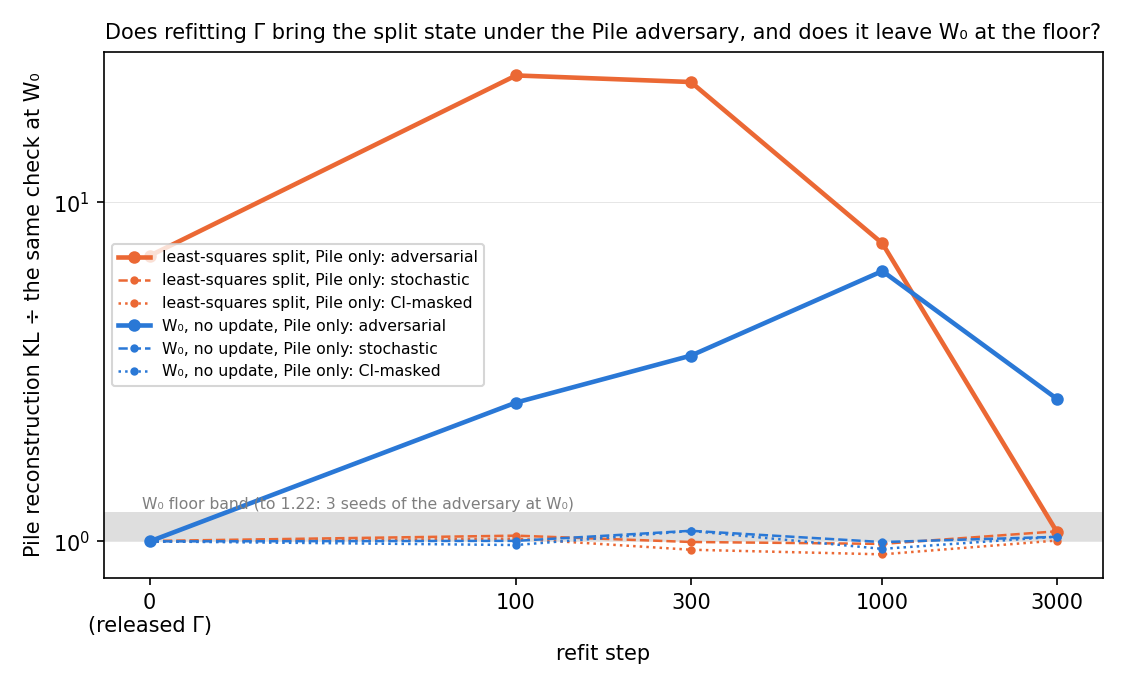

In [2]:
display(Image(F / 'pgd_vs_step.png', width=900))

**Reading it.** Yes at the last checkpoint, but the control on the same axes shows the refit recipe moving the ratio on its own. The split state, in orange, starts at seven times the attacker's damage at the unchanged model and reads 24 after 100 refit steps. It is still 23 at step 300, then falls to 7.6 at step 1,000 and into the floor band at step 3,000. The unchanged model under the same refit, in blue, leaves the band at the first checkpoint and reads between 2.6 and 6.3 at every checkpoint after it. For both states the stochastic and CI-masked ratios, the dashed and dotted lines, stay within 8 percent of 1, so only the attacker sees any of this. A refit that breaks the released Γ's adversarial check on the model it was fitted to is not a recipe whose other arms can be read. The split's fall to the floor sits on top of that drift and is not a repair.

In [3]:
rows = [(word, int(s), round(c[s]['pile']['pgd_kl'], 2), round(c[s]['pile']['stochastic_kl'], 3), round(c[s]['pile']['ci_masked_kl'], 3),
         round(c[s]['sparsity_ratio'], 3))
        for word, c in (('least-squares split', ck), ('W₀, no update (control)', ckw)) for s in steps]
pd.DataFrame(rows, columns=['state', 'refit step', 'adversarial ratio', 'stochastic ratio', 'CI-masked ratio', 'sparsity loss ÷ W₀'])

,state,refit step,adversarial ratio,stochastic ratio,CI-masked ratio,sparsity loss ÷ W₀
0,least-squares split,0,6.96,1.003,0.997,0.998
1,least-squares split,100,23.67,1.040,1.019,0.951
2,least-squares split,300,22.64,0.996,0.945,0.969
3,least-squares split,1000,7.57,0.983,0.916,1.091
4,least-squares split,3000,1.06,1.071,1.006,1.601
5,"W₀, no update (control)",0,1.00,1.000,1.000,1.000
6,"W₀, no update (control)",100,2.57,1.004,0.976,0.944
7,"W₀, no update (control)",300,3.53,1.075,1.074,1.020
8,"W₀, no update (control)",1000,6.27,0.996,0.951,1.014
9,"W₀, no update (control)",3000,2.63,1.032,1.033,1.092


### 2. What did Γ change to get there?

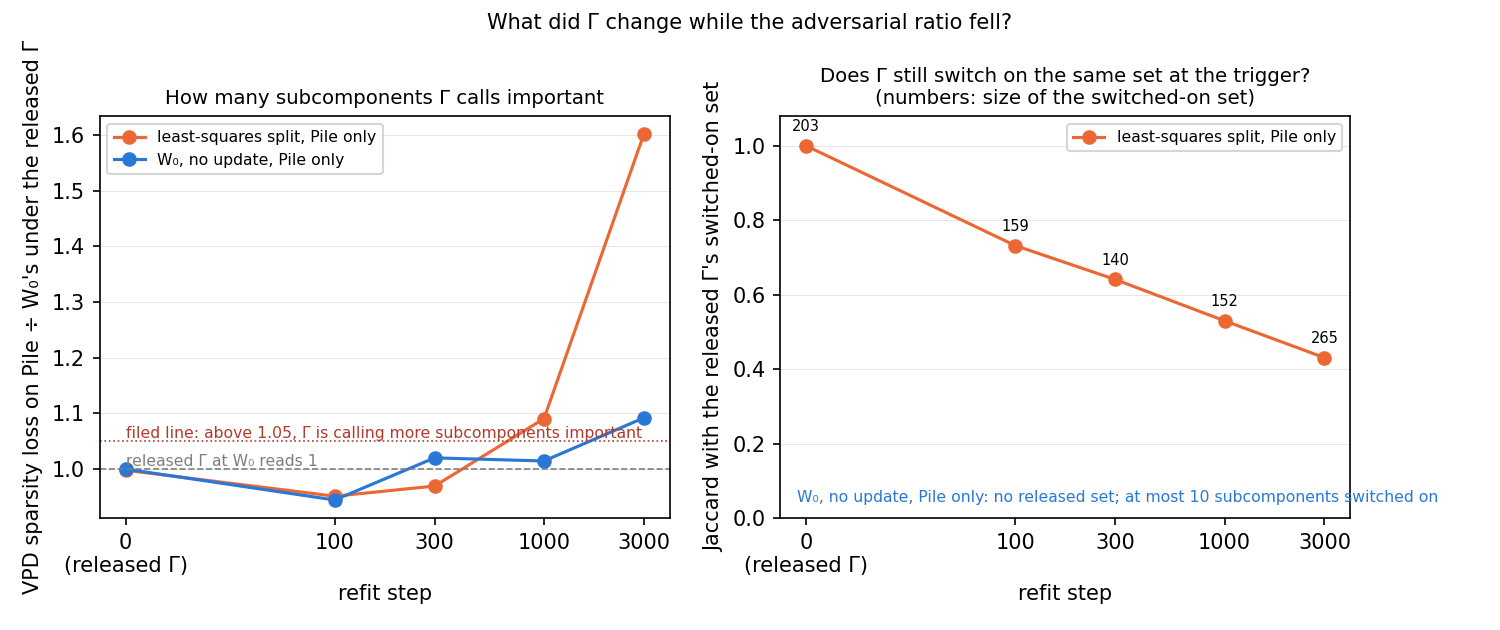

In [4]:
display(Image(F / 'gamma_changes.png', width=1100))

**Reading it.** Γ reached the floor by calling more subcomponents important, which the plan filed as the cheating branch. The left panel is VPD's sparsity loss on the Pile rows, divided by the original model's. For the split state it dips to 0.95 by step 100 and is back near 1 at step 300. Then it climbs to 1.09 at step 1,000 and 1.60 at step 3,000, far past the filed line of 1.05. The right panel is the trigger. The set Γ switches on there shrinks from 203 subcomponents to 140 by step 300, then grows to 265 by step 3,000. Its overlap with the released Γ's set falls at every checkpoint, to a Jaccard of 0.43. The route split moved the same way. The share of the behaviour carried by existing subcomponents that Γ switches on rose from 0.60 to 0.75 by step 300 and fell back to 0.51 at step 3,000. The masked-off share did the reverse. At the last checkpoint the CI-masked model's probability of the target is 0.89, down from 0.93 under the released Γ. The control moves far less on both panels. Its sparsity loss dips to 0.94 at step 100 and ends at 1.09. At the trigger, where the unchanged model has no behaviour, it switches on at most 10 subcomponents. So the split state's sixty percent rise is the state's own, on top of a recipe that drifts by nine percent.

In [5]:
rows = [(int(s), round(ck[s]['routes']['shares']['r'], 2), round(ck[s]['routes']['shares']['e_gate'], 2), round(ck[s]['routes']['shares']['e_delta'], 2),
         round(ck[s]['routes']['p_cells']['L11'], 3)) for s in steps]
pd.DataFrame(rows, columns=['refit step', 're-switching share', 'masked-off share', 'share left in Δ', 'CI-masked P(target) at the trigger'])

,refit step,re-switching share,masked-off share,share left in Δ,CI-masked P(target) at the trigger
0,0,0.60,0.26,0.09,0.934
1,100,0.71,0.14,0.09,0.981
2,300,0.75,0.09,0.09,0.989
3,1000,0.75,0.07,0.09,0.991
4,3000,0.51,0.31,0.09,0.894


### 3. Did the refit converge?

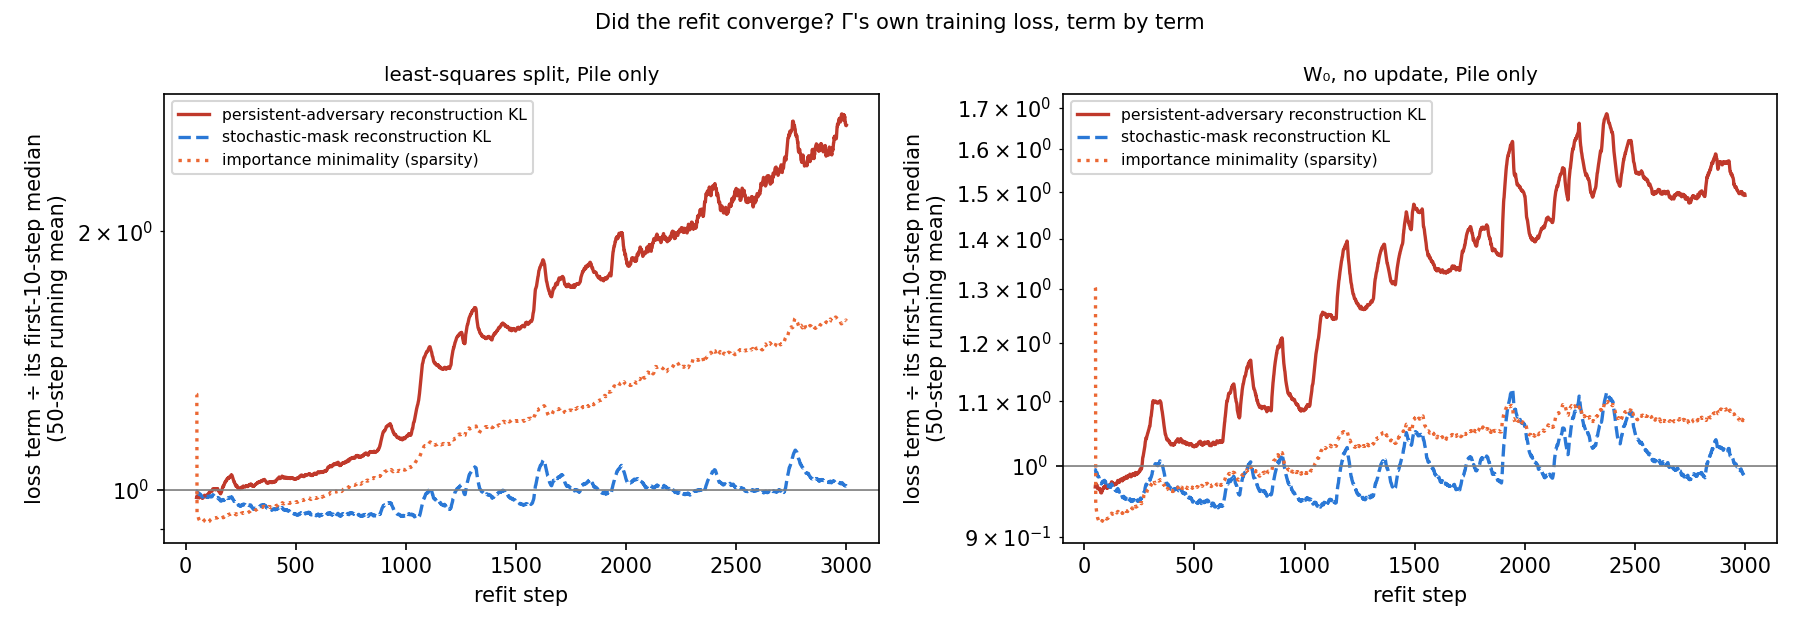

In [6]:
display(Image(F / 'refit_loss.png', width=800))

**Reading it.** No, on either state. Each line is one term of Γ's own training loss, relative to its first ten steps. On the split state, left, the persistent-adversary term rises from step 200 on and ends at two and a half times its start; the sparsity term ends at 1.7 times; the stochastic term is flat. The unchanged model, right, has the same shape at lower amplitude: the persistent-adversary term rises from about step 300 to 1.5 times its start, and the sparsity term ends 7 percent up. Both runs jump on step 2, when the sparsity term goes from 850 to 16,000 before recovering, the signature of an optimiser restarted at ten times the rate the released schedule ended on. So neither Γ is a fit. The 3,000-step Γ on the split is one that the harness's fresh 20-step attacker can no longer hurt while the attacker inside its own objective hurts it more at every step. The persistent adversary starts every refit from random sources, where the released run's had four hundred thousand steps to strengthen; a loss that rises for the whole run is what an adversary catching up looks like. A hot warm start against a weak adversary is the shape of the drift, but that is the hypothesis the next design tests, not a finding of this run.

### 4. Stage 0: do the turned-down subcomponents matter more at the updated model?

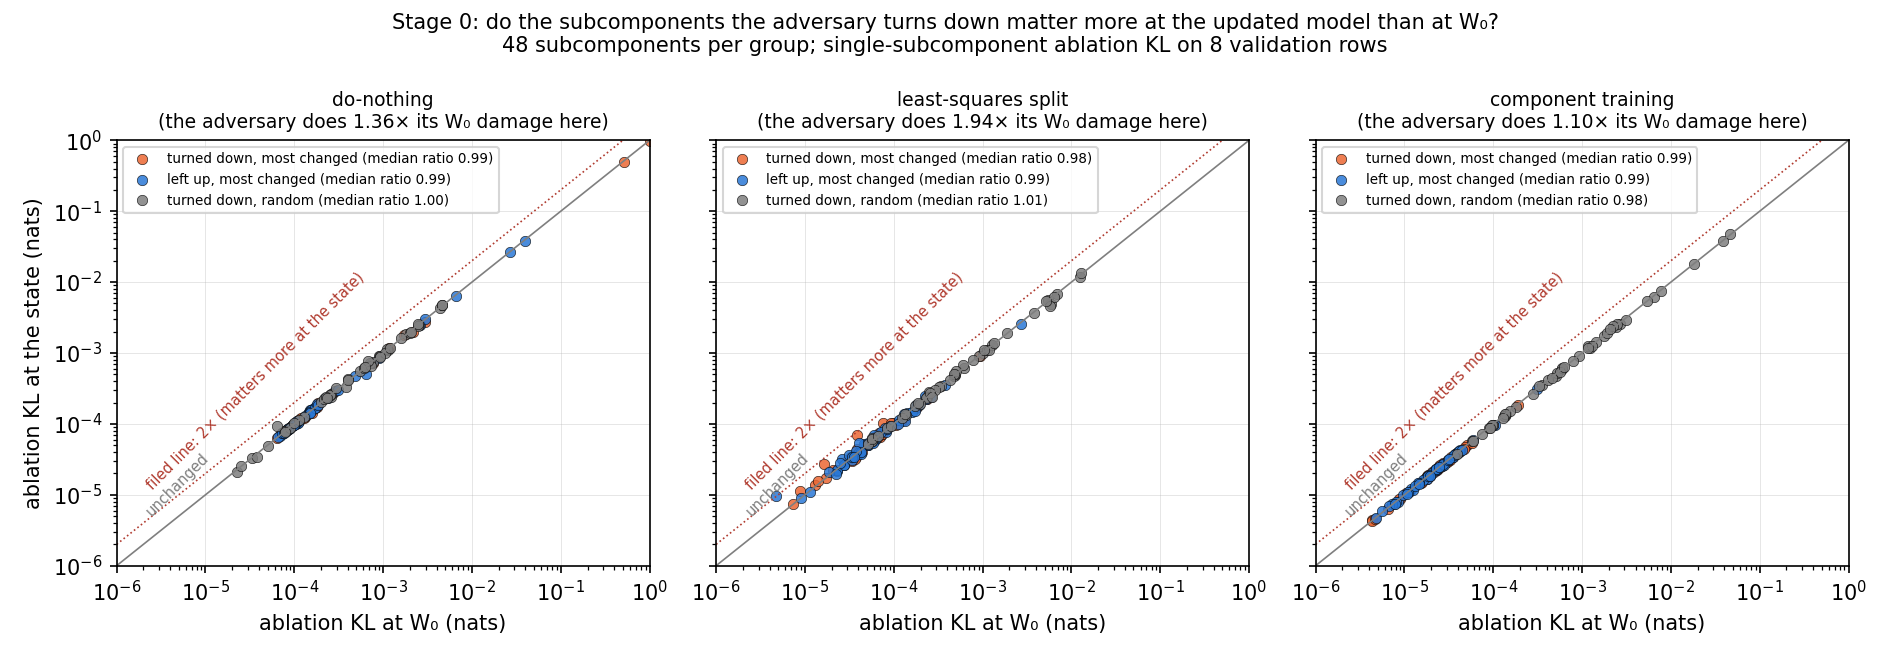

In [7]:
display(Image(F / 'stage0_ablation.png', width=1200))

**Reading it.** No. Every point sits on the diagonal. Ablating one of the 48 most-changed subcomponents the attacker turns down costs the same at the split state as at the original model, a median ratio of 0.98. The two other groups read 0.99 and 1.01. Those turned-down changed subcomponents are near-inert singly, about a ten-thousandth of a nat each, and the released Γ already gives them an importance near zero. Yet the attacker's joint mask does 1.9 times its original damage at the split state. And the masks do not transfer: the original model's mask does no extra damage at the split state, and the split state's mask does none at the original. So the fragility is a joint effect of many individually inert changes, specific to the state. That is what cancellation looks like, not what a stale importance value looks like. Do-nothing's "most changed" group is a tie-break artefact, since none of its subcomponents change; its random group carries that panel.

In [8]:
w0 = out['stage0']['w0']['pgd_kl']
rows = []
for name, word in (('nothing', 'do-nothing'), ('ls', 'least-squares split'), ('ct', 'component training')):
    s = out['stage0'][name]
    g = s['groups']
    rows.append((word, round(s['pgd_kl'] / w0, 2), round(s['w0_sources_at_state'] / w0, 2), round(s['state_sources_at_w0'] / w0, 2),
                 round(g['down_changed']['summary']['median_ratio'], 2), round(g['up_changed']['summary']['median_ratio'], 2), round(g['down_random']['summary']['median_ratio'], 2)))
pd.DataFrame(rows, columns=['state', "attacker's damage ÷ W₀'s", "W₀'s mask at the state ÷ W₀'s", "state's mask at W₀ ÷ W₀'s",
                            'turned down, changed: median ablation ratio', 'left up, changed', 'turned down, random'])

,state,attacker's damage ÷ W₀'s,W₀'s mask at the state ÷ W₀'s,state's mask at W₀ ÷ W₀'s,"turned down, changed: median ablation ratio","left up, changed","turned down, random"
0,do-nothing,1.36,1.01,1.08,0.99,0.99,1.00
1,least-squares split,1.94,1.00,1.02,0.98,0.99,1.01
2,component training,1.10,1.01,1.06,0.99,0.99,0.98


### 5. The protocol test: does a warmed adversary and the end-of-schedule rate keep W₀ at the floor?

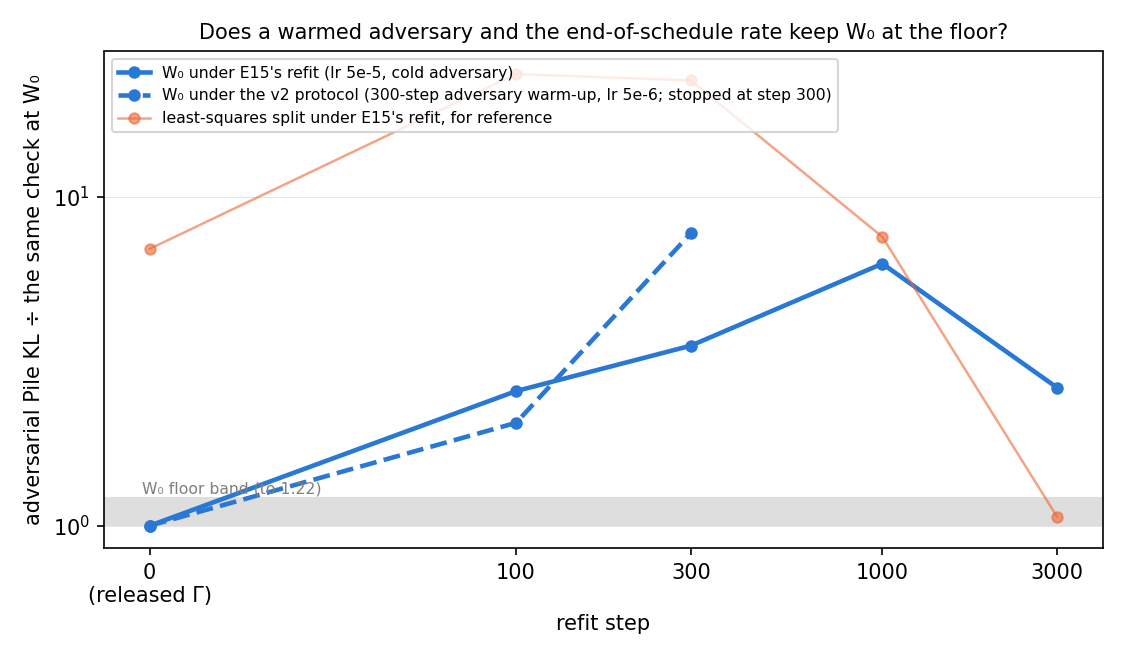

In [9]:
display(Image(F / 'protocol_vs_step.png', width=900))

**Reading it.** No. The second protocol runs 300 steps with Γ's learning rate at zero, so the persistent adversary and the optimiser's moments warm up, then trains Γ at the released end-of-schedule rate, ten times smaller than before. On the unchanged model its adversarial ratio reads 2.1 at step 100 and 7.8 at step 300, the dashed line, against 2.6 and 3.5 under the first recipe. The run was stopped at step 300 by the early-stop rule, before the credits ran out. The two things the protocol was built to fix did get fixed. The persistent adversary's loss flattened at 0.42 nats by step 50 of the warm-up and stayed there, and the first training steps show no spike. Even so, Γ left the floor within 100 steps, at a rate that moves each parameter by at most 5e-4 per step. The other checks held as before, the stochastic ratio at 0.99 and the CI-masked at 0.94, and the sparsity loss fell by 3 percent. The number that explains the failure is the adversary's plateau. The refit's own attacker reaches 0.42 nats on the released Γ, where the harness's fresh 20-step attacker reaches 0.70 on the same Γ. After 300 refit steps the harness's attacker reaches 9.4 nats on one block of rows while the refit's attacker still reads 0.43. The objective as reconstructed does not see what the harness measures, so nothing in it holds the harness's floor, and the importance term is free to lower the values the attacker's box is built from.

In [10]:
v2 = json.loads((R / 'gamma_refit_v2.json').read_text())['partial']['w0_P']['checkpoints']  # stopped at step 300
rows = [(int(s), round(c['pile']['pgd_kl'], 2), round(c['pile']['stochastic_kl'], 3), round(c['pile']['ci_masked_kl'], 3), round(c['sparsity_ratio'], 3))
        for s, c in sorted(v2.items(), key=lambda kv: int(kv[0]))]
pd.DataFrame(rows, columns=['Γ step', 'adversarial ratio', 'stochastic ratio', 'CI-masked ratio', 'sparsity loss ÷ W₀'])

,Γ step,adversarial ratio,stochastic ratio,CI-masked ratio,sparsity loss ÷ W₀
0,0,1.00,1.000,1.000,1.000
1,100,2.06,0.994,0.954,0.968
2,300,7.76,0.988,0.939,0.975


## What we learned

Letting Γ see the new model is not yet a map, and the refit itself is the first thing to fix. The same refit that took the split state to the floor takes the unchanged model off it. So the recipe moves the adversarial ratio on its own, and the split's curve cannot be read as the state's. What the control does not undo is the sparsity reading. Γ on the split state ended calling sixty percent more subcomponents important, where the control's count rose nine percent, so the cheating reading stands as the state's share of the drift. Stage 0 settles the narrower question the plan put first. The attacker is not exploiting subcomponents that matter more at the new model than Γ says, because they matter equally little at both. It is exploiting a joint structure among many inert changes that exists only at the split state. That is the cancellation reading of the fragility, and it says a Γ update alone would not remove the encoding even if it converged. For the weak version this moves the question from "is Γ stale" to "is the split's spread of the update over many subcomponents the thing to avoid", which the adjoint split and component training already do differently.

The second protocol closes the question for now. With the adversary warmed and the rate at the released end value, the unchanged model still leaves the floor within 100 steps, and the refit's own attacker never notices: it plateaus at 0.42 nats where the harness's reaches 0.70 on the same Γ. A refit on this objective cannot hold the harness's floor, so refitting Γ alone is shelved, and the question moves to the cancellation tests on the saved split state.

## What went wrong

The refit was not the warm start it was meant to be, and the control that would have shown that ran second. Two parts of the recipe differed from the released run's end state. The optimiser restarted at the released starting rate, ten times where its schedule ended, with empty moment estimates. Adam's first update is then a sign step on every parameter, which is the twenty-fold spike of the sparsity term on step 2. The persistent adversary restarted from random sources with two warm-up steps, where the released run's sources had four hundred thousand steps to strengthen. While it was weak, the sparsity term was the main force on Γ, so Γ called fewer subcomponents important by step 100, and the harness's fresh attacker found the holes. The arm order made it expensive: the split state ran first and the control second, so ten dollars went on a curve nobody could read. The rerun fixes the recipe rather than the state. It runs three hundred steps with Γ's learning rate at zero, so the adversary and the optimiser's moments warm up, then trains at the released end-of-schedule rate. It is tested on the unchanged model alone, and no state runs again until that control stays at the floor. Whether this explanation is right is what that run decides.

## How compelling is the evidence

One task, one fine-tune seed, one refit seed, one card. The refit result now has its control, and the control failed. That is a firm negative about the recipe, and it leaves the split's curve unreadable rather than read. Do-nothing, component training, the adjoint split and the task-mixed arm were cut when the benchmark came in at 2.3 seconds per step, six times the plan's arithmetic, and they should not run under this recipe. The Pile checks are blind to the trigger, and the Pile-only refit saw about three trigger positions in 131 thousand, so the trigger-set numbers describe a Γ that still never saw one. The attacker in the harness is a fresh 20-step one, and the refit optimises against a persistent one. A Γ that defeats the first while losing to the second is a measurement caution as much as a result. Stage 0 is stronger: 48 subcomponents per group on three states, with the random group as its own reference and the diagonal as the null, and the ablation KLs are a hundred times their spread. It ablates on 8 validation rows with a weaker attacker that shares one mask across positions, so its ratios are not the harness's.

## Surprises

**Something unexpected happened that I cannot explain.** The unchanged model's refit was predicted to stay at the floor with its sparsity loss within one percent. Instead its adversarial ratio read 2.6 at the first checkpoint and 6.3 at step 1,000, while every other check held. The first run's surprise, the split's ratio rising to 24 before it fell, is now partly accounted for. The recipe alone moves the ratio by a factor of three to six. What the recipe does to Γ is not established. The loss curves point at a hot warm start against an adversary that starts from random sources. The signs are the twenty-fold spike on the second step and a persistent-adversary term that rises for the whole run on both states. That is a hypothesis for the next design, not a finding.

A third, from the protocol test. The persistent adversary, given 300 steps on a frozen Γ, flattened at 0.42 nats, well below the 0.70 that the harness's 20-step attacker reaches on the same Γ from a random start. The plan expected it to reach at least that. The refit's attacker has more freedom, one source per row and position, and still does less damage. Whether that is its step size, the sources being stepped once per batch on changing data, or something in the released objective itself, this run cannot say.

Two smaller ones. The plan's plateau rule, the first checkpoint whose ratio changes by less than a tenth to the next, fires at step 100, after which the ratio fell twenty-fold; the rule is unusable on a curve that rises first. And the smoke benchmark at batch 4 projected 0.37 seconds per step while the real batch took 2.29. A budget set from the arithmetic was wrong by six, and the run was cut to one refit under the user's cap.

## What next

- **Refitting Γ alone is shelved** (`decisions.md`, 2026-10-21): two protocols took the unchanged model off the floor, and the refit's attacker is weaker than the harness's, so the objective as reconstructed cannot hold the floor. Reopened only by a refit whose attacker matches the harness's, which is re-deriving VPD's recipe and not the goal.
- **The cancellation tests on the saved split state**, with no GPU: the coherence of the per-subcomponent changes and a half-revert against the full revert. Stage 0 predicts coherence well below 1 and a half-revert that hurts more than the full one.
- **The remaining four arms** are shelved with the refit.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | the split state is the fine-tune at the trigger | P(target) equal to 1e-3, route shares sum to 1 | difference 3e-8, sum 1.000000 | pass |
| G2 | the harness reproduces the unchanged model | every Pile ratio within 0.02 of 1 at W₀, sparsity within 0.001 | every ratio 1.000 and sparsity 1.000 at the control's step 0 | pass |
| P1 | the unchanged model's refit stays at the floor | adversarial ≤ 1.22 and sparsity in [0.99, 1.01] at every checkpoint | adversarial 2.57, 3.53, 6.27, 2.63; sparsity 0.944, 1.020, 1.014, 1.092 | fail at every checkpoint: the filed null, the recipe drifts |
| P1 v2 | the unchanged model stays at the floor under the second protocol | the same rule | adversarial 2.06, 7.76 at steps 100, 300; sparsity 0.968, 0.975; stopped at 300 | fail: the filed "drifts the same" branch |
| W1 | the adversary flattens by warm-up step 300 | mean over steps 201–300 within 5% of steps 101–200 | logged 0.41, 0.42, 0.42 at steps 100, 200, 300; the full curve was not written | pass, at 0.42 nats against an expected 0.6 or more |
| W2 | no spike on the first Γ steps | within 20% of the last 10 warm-up steps | 855 and 819 against about 840 | pass |
| P2 | do-nothing cannot move | adversarial at 3,000 ≤ 1.22 × its step 0 | not run | not run |
| P3 | the split state improves part way | adversarial at 3,000 ≤ half of step 0, above 1.22, sparsity ≤ 1.05 | 1.06 ≤ 3.48, below 1.22, sparsity 1.60 | fail: cheating branch, on a recipe that drifts |
| P3 plateau | first checkpoint changing < 10% to the next | reported | step 100 (24 → 23), then a 20-fold fall | rule unusable |
| P4 | component training keeps passing | adversarial ≤ 1.22 at every checkpoint | not run | not run |
| P5 | the adjoint split | reported | not run | not run |
| P6 | the task-mixed arm agrees on Pile and re-gates the trigger more | within 20% on Pile, lower Jaccard | not run | not run |
| S0 | turned-down changed subcomponents are inert at both | median ablation ratio < 2 | 0.98, with released importance 7e-4 | pass: cancellation reading |

## Not run

- Four of the six refits: do-nothing, the task-mixed split, component training and the adjoint split. The benchmark read 2.29 s per step and 53.7 GB, projecting 11.5 hours for six refits; the first pod's cap fit one refit and the second pod ran the control. The states of all five are on disk; the four arms are shelved with the refit.
- The second protocol's steps 1000 and 3000: the run was stopped after the step-300 evaluation by the early-stop rule, with the RunPod credits running out. Its loss curve is not in the JSON, which writes it only at a refit's end; the logged points at steps 1, 2, 5, 10, 20, 50, 100, 200 and 300 of each phase are in `results/large/full_v2.log`.
- The second update seed, the ladder task where component training fails worst, and any refit of U, V or Δ.
- The saved mean importance per subcomponent at each checkpoint and the trigger gates at steps 0 and 3,000 are on disk and not yet looked at.

## Provenance

Results `experiments/gamma_refit/results/gamma_refit.json`, sha256 bffd7897…, both refits; smoke `gamma_refit_smoke.json`; logs `results/large/full.log` and `full_run2.log`, on the pods' clocks in UTC. States, stage-0 sources, both refit Γs' parameters in bf16, 1.1 GB each, mean importances and trigger gates in `results/large/`. Two RunPod H100 80 GB secure pods at $3.99/h on 2026-10-20: 16:48 to 19:18 BST, $10.07, prep 378 s and the split's refit 7,184 s; 20:09 to 22:26 BST, $9.10, prep re-run 351 s and the control's refit 7,212 s. Code `src/commute/gamma.py` and `experiments/gamma_refit/run.py`. Third pod, the protocol test (`all --v2 --only w0_P`): the same card, 10:41 to 11:30 BST on 2026-10-21, $3.35; smoke 105 s, prep 374 s (benchmark 2.31 s/step, 53.7 GB), the refit killed after the step-300 evaluation. Results `results/gamma_refit_v2.json` (`51bb108fe8c0ebd8…`, under `partial.w0_P`), logs `results/large/full_v2.log` and `scored_stdout_v2.log`, `trigger_gates_w0_P_step0_v2.pt`; predictions `results/predictions_v2.json`; code `gamma.py` and `run.py` with the `--v2` protocol (`reports/plans/2026-10-21_plan_gamma-refit-protocol.md` § Built).